In [2]:
import math, time, numpy as np, pandas as pd, matplotlib.pyplot as plt
import torch, torch.nn as nn, torch.nn.functional as F
from torchvision.datasets import EuroSAT
from sklearn.model_selection import train_test_split

device = 'cuda' if torch.cuda.is_available() else 'cpu'
print('device:', device, '| torch', torch.__version__)
if device == 'cpu':
    print('WARNING: no GPU. Training would take hours: Runtime -> Change runtime type -> GPU.')
torch.backends.cudnn.benchmark = True  # faster convolutions on GPU
plt.rcParams['figure.figsize'] = (10, 4)

# every design choice in one place, fixed BEFORE looking at any test result
PATCH, DIM, DEPTH, HEADS, MLP_RATIO = 8, 128, 3, 4, 2  # tiny ViT: 64x64 image -> 8x8 = 64 patch tokens
STEPS, BATCH, LR, WD = 2000, 128, 1e-3, 0.05  # same recipe and same number of steps for every run
SIZES = {'small': 50, 'medium': 250, 'all': None}  # training images per class (None = the whole training set)
SEEDS = (0, 1, 2)  # each run is repeated with three seeds

device: cpu | torch 2.11.0+cpu


100%|██████████| 94.3M/94.3M [00:00<00:00, 114MB/s]


loaded 27,000 images in 8 s; shape (27000, 64, 64, 3)


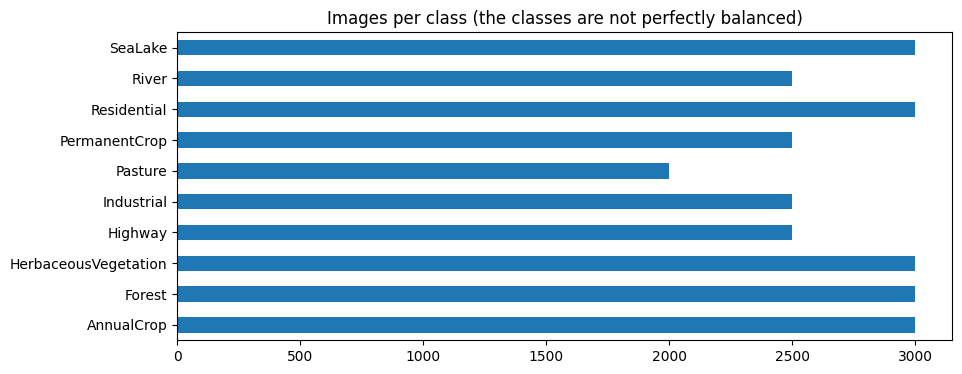

In [3]:
ds = EuroSAT(root='data', download=True)
classes = ds.classes
t0 = time.time()
X_all = np.stack([np.asarray(ds[i][0], dtype=np.uint8) for i in range(len(ds))])
y_all = np.asarray(ds.targets)
print(f'loaded {len(X_all):,} images in {time.time() - t0:.0f} s; shape {X_all.shape}')
assert X_all.shape == (27000, 64, 64, 3) and len(classes) == 10  # 27,000 RGB images, 64 x 64

counts = pd.Series(y_all).value_counts().sort_index()
counts.index = classes
counts.plot.barh(title='Images per class (the classes are not perfectly balanced)'); plt.show()